# Deep Learning 5

## PyTorch Lightning: uma rede para (quase) qualquer coisa

Link Colab

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ftl-brazil-2026/ebook/blob/main/deep-learning/dl5_lightning_qualquer_coisa.ipynb)

Na aula 4 montamos o pipeline completo à mão (`Dataset`, `DataLoader`, loop de treino, loop de avaliação) e
depois vimos o mesmo pipeline no Lightning. Hoje vamos mostrar **por que** o Lightning vale a pena: com um único
`LightningModule` genérico, vamos treinar redes para problemas completamente diferentes.

A ideia central da aula:

> Todo problema de Deep Learning supervisionado é a combinação de **3 peças**: os **dados**, a **rede** e a
> **perda**. O resto (laço de treino, validação, *early stopping*, salvar o melhor modelo, registrar métricas,
> GPU...) é sempre igual, e o Lightning cuida disso.

**Roteiro**

1. `LightningDataModule`: como os dados se organizam em um objeto
2. Um `LightningModule` genérico
3. Os superpoderes do `Trainer` (callbacks, logger, *smoke test*, busca de taxa de aprendizado)
4. Cinco problemas, o mesmo código:
   - classificação 2D (duas luas)
   - regressão em tabela (progressão de diabetes)
   - previsão de série temporal (LSTM)
   - classificação de imagens (rede convolucional)
   - autoencoder: aprender **sem rótulos**
5. Acompanhando o treino no Weights & Biases

In [1]:
# no Google Colab, o PyTorch já vem instalado; o Lightning não
import sys
if "google.colab" in sys.modules:
    !pip install -q lightning

In [ ]:
import io
import os
import time
import contextlib
import logging
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, TensorDataset, random_split
from torchvision import datasets, transforms
from sklearn.datasets import make_moons, load_diabetes

import lightning as L
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
from lightning.pytorch.loggers import CSVLogger
from lightning.pytorch.tuner import Tuner
from lightning.pytorch.utilities.model_summary import ModelSummary


AZUL, LARANJA, VERDE, CINZA, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#898781", "#52514e"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": CINZA, "axes.labelcolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA,
    "axes.grid": True, "grid.color": "#e6e5e1", "figure.dpi": 110,
})

# saída do Lightning mais limpa para a aula
logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)
logging.getLogger("lightning.fabric").setLevel(logging.ERROR)
for aviso in [".*does not have many workers.*", ".*GPU available but not used.*", ".*LeafSpec.*",
              ".*smaller than the logging interval.*", ".*Checkpoint directory.*exists.*"]:
    warnings.filterwarnings("ignore", aviso)

# CPU é mais rápida que a GPU do Mac (MPS) para redes pequenas; no Colab com GPU, usamos CUDA
ACELERADOR = "gpu" if torch.cuda.is_available() else "cpu"
L.seed_everything(42)
print(f"Lightning {L.__version__}, acelerador: {ACELERADOR}")

Lightning 2.6.6, acelerador: cpu


## Como o Lightning organiza o treino

O Lightning não muda o PyTorch: ele **separa** o código de um projeto em três objetos, cada um com uma
responsabilidade. Você escreve o que é específico do seu problema em métodos com nomes fixos, e o Lightning
chama esses métodos na hora certa.

```
┌──────────────────────────────┐      ┌──────────────────────────────────┐
│  LightningDataModule         │      │  LightningModule                 │
│  "OS DADOS"                  │      │  "O MODELO"                      │
│                              │      │                                  │
│  prepare_data()  → baixar    │      │  __init__()   → a rede           │
│  setup()         → Datasets, │      │  forward()    → previsão         │
│                    divisão,  │      │  training_step()   → perda       │
│                    padronizar│      │  validation_step() → métricas    │
│  train_dataloader()          │      │  test_step()                     │
│  val_dataloader()            │      │  configure_optimizers()          │
│  test_dataloader()           │      │                → otimizador      │
└──────────────┬───────────────┘      └────────────────┬─────────────────┘
               │                                       │
               └──────────────────┬────────────────────┘
                                  ▼
               ┌──────────────────────────────────────────┐
               │  Trainer  "O MOTOR"                       │
               │  laço de épocas e lotes, CPU/GPU,         │
               │  callbacks (early stopping, checkpoint),  │
               │  logger (CSV, TensorBoard, W&B)           │
               │                                           │
               │  trainer.fit(modelo, datamodule=dm)       │
               │  trainer.test(...)   trainer.predict(...) │
               └──────────────────────────────────────────┘
```

### Onde colocar cada coisa

| O quê | Onde | Nesta aula |
|---|---|---|
| Baixar os dados | `LightningDataModule.prepare_data()` | `MNISTDataModule.prepare_data` |
| Criar os `Dataset`s, dividir treino/val/teste, padronizar | `LightningDataModule.setup()` | `TabelaDataModule.setup` |
| `DataLoader`s (tamanho do lote, embaralhamento) | `train_dataloader()`, `val_dataloader()`, `test_dataloader()` | `batch_size=32`, `shuffle=True` só no treino |
| A arquitetura da rede | `LightningModule.__init__()` (criada lá dentro ou recebida como argumento) | `self.rede = rede` |
| Como a rede faz uma previsão | `forward()` | `return self.rede(x)` |
| A **perda** | `training_step()`: calcula e **devolve** a perda | `self.perda(saida, y)` |
| Métricas | `training_step()`, `validation_step()`, `test_step()` com `self.log(...)` | acurácia, MAE |
| **Otimizador** (e *scheduler* de lr) | `configure_optimizers()` | `torch.optim.Adam(self.parameters(), lr=self.lr)` |
| Nº de épocas, CPU/GPU, precisão | `Trainer(max_epochs=..., accelerator=..., precision=...)` | função `treina` |
| *Early stopping*, salvar o melhor modelo | `Trainer(callbacks=[EarlyStopping(...), ModelCheckpoint(...)])` | função `treina` |
| Onde registrar as métricas | `Trainer(logger=...)` | `CSVLogger` (e W&B no fim da aula) |
| Treinar, testar, prever | `trainer.fit()`, `trainer.test()`, `trainer.predict()` | |

### O que o `trainer.fit()` faz por baixo dos panos

Em pseudo-código, o `trainer.fit(modelo, datamodule=dm)` executa essencialmente o laço que escrevemos à mão na
aula 4, chamando os **seus** métodos:

```python
dm.prepare_data()                          # 1. baixa os dados
dm.setup("fit")                            # 2. cria os Datasets
modelo.to(device)                          # 3. leva a rede para CPU/GPU
otimizador = modelo.configure_optimizers()

# 4. "sanity check": roda 2 lotes de validação ANTES de treinar, para achar bugs na validação cedo
for epoca in range(max_epochs):
    modelo.train()                                            # modo de treino
    for i, lote in enumerate(dm.train_dataloader()):
        lote = mover_para(device, lote)
        perda = modelo.training_step(lote, i)                 # ← o seu código
        otimizador.zero_grad()
        perda.backward()
        otimizador.step()

    modelo.eval()                                             # modo de avaliação
    with torch.no_grad():
        for i, lote in enumerate(dm.val_dataloader()):
            modelo.validation_step(lote, i)                   # ← o seu código

    # 5. fecha a época: tira a média dos self.log(..., on_epoch=True) e envia ao logger
    # 6. callbacks: ModelCheckpoint salva se val_perda melhorou; EarlyStopping decide se para
```

### Comportamentos importantes do Lightning

- **Você não chama** `.to(device)`, `zero_grad()`, `backward()`, `step()`, `model.train()`, `model.eval()` nem
  `torch.no_grad()`: o `Trainer` faz isso. O `training_step` só precisa **devolver a perda**.
  (Para casos especiais, como GANs com dois otimizadores, existe a otimização manual:
  `self.automatic_optimization = False`.)
- `self.log("nome", valor, on_step=..., on_epoch=...)`: com `on_epoch=True`, o Lightning tira a **média** do valor
  em todos os lotes da época (ponderada pelo tamanho do lote) e registra um número por época.
- O nome que você dá no `self.log` é o que os callbacks enxergam: `EarlyStopping(monitor="val_perda")` só funciona
  porque o `validation_step` registra `"val_perda"`.
- `self.save_hyperparameters()` guarda os argumentos do `__init__` (como o `lr`) dentro do checkpoint, para
  recarregar o modelo depois com `load_from_checkpoint`.
- `trainer.test(..., ckpt_path="best")` recarrega o **melhor** checkpoint salvo antes de testar.
- Cada execução cria uma pasta `logs/<nome>/version_N/` com as métricas (`metrics.csv`), os hiperparâmetros
  (`hparams.yaml`) e os checkpoints.

## 1. `LightningDataModule`: todos os dados em um objeto

Na aula 4, os dados estavam espalhados: um `Dataset`, um `random_split`, três `DataLoader`s. 

Com o pytorch lightning, conseguimos organizar tudo isso em uma estrutura unica chamada:
`LightningDataModule`, que junta tudo em uma classe com métodos de nome fixo:

| Método | Responsabilidade |
|---|---|
| `prepare_data()` | baixar os dados|
| `setup(stage)` | dividir treino/validação/teste, padronizar |
| `train_dataloader()` | o `DataLoader` de treino (com embaralhamento) |
| `val_dataloader()` / `test_dataloader()` | os `DataLoader`s de validação e teste |

Vamos escrever dois. O primeiro serve para **qualquer tabela** de números (`X`, `y`) e já faz o que aprendemos
nas aulas de Machine Learning: divide os dados (de forma aleatória ou **temporal**) e padroniza usando **só a
média e o desvio do treino**.

In [3]:
class TabelaDataModule(L.LightningDataModule):
    """Recebe X e y (tensores) e cuida da divisão treino/val/teste, da padronização e dos DataLoaders."""

    def __init__(self, X, y, batch_size=32, 
                 frac_val=0.15, frac_teste=0.15,
                 padroniza_x=True, 
                 padroniza_y=False, 
                 temporal=False, 
                 seed=42):
        super().__init__()
        self.X, self.y = X.float(), y
        self.batch_size, self.frac_val, self.frac_teste = batch_size, frac_val, frac_teste
        self.padroniza_x, self.padroniza_y, self.temporal, self.seed = padroniza_x, padroniza_y, temporal, seed

    # aqui a funcao padrao do lightning onde organiza toda a estrutura dos dados
    def setup(self, 
              stage=None):
        if hasattr(self, "treino"):                  # setup é uma requisição do lightning
            return
        # mede o tamanho do conjunto de treino
        n = len(self.X)
        # calcula a fracao que vai pra treino e a fracao pra teste 
        n_teste, n_val = int(n * self.frac_teste), int(n * self.frac_val)
        n_treino = n - n_val - n_teste
        # ajeitando aqui para dados temporais, lembrando que a divisao nao pode ser aleatoria 
        idx = torch.arange(n) if self.temporal else torch.randperm(n, generator=torch.Generator().manual_seed(self.seed))
        tr, va, te = idx[:n_treino], idx[n_treino:n_treino + n_val], idx[n_treino + n_val:]

        X, y = self.X.clone(), self.y.clone()
        if self.padroniza_x:                         # média e desvio calculados SÓ no treino #stardadization
            self.x_media, self.x_desvio = X[tr].mean(0), X[tr].std(0)
            X = (X - self.x_media) / self.x_desvio
        if self.padroniza_y:
            self.y_media, self.y_desvio = y[tr].mean(0), y[tr].std(0)
            y = (y - self.y_media) / self.y_desvio
        self.treino, self.val, self.teste = TensorDataset(X[tr], y[tr]), TensorDataset(X[va], y[va]), TensorDataset(X[te], y[te])

    def train_dataloader(self):
        return DataLoader(self.treino, 
                          batch_size=self.batch_size, 
                          shuffle=True,
                          generator=torch.Generator().manual_seed(self.seed))

    def val_dataloader(self):
        return DataLoader(self.val, batch_size=1024)

    def test_dataloader(self):
        return DataLoader(self.teste, batch_size=1024)

O segundo é para o MNIST, e mostra o `prepare_data` (download). Ele também tem uma opção `autoencoder`, em vez
de `(imagem, rótulo)`, cada amostra vira `(imagem, imagem)`. Vamos usá-la no último problema.

In [4]:
class ParesIguais(Dataset):
    """Embrulha um dataset de imagens para devolver (imagem, imagem)"""
    def __init__(self, base):
        self.base = base
    def __len__(self):
        return len(self.base)
    def __getitem__(self, i):
        x, _ = self.base[i]
        return x, x


class MNISTDataModule(L.LightningDataModule):
    def __init__(self, batch_size=128, autoencoder=False):
        super().__init__()
        self.batch_size, self.autoencoder = batch_size, autoencoder

    def prepare_data(self):                          # só baixa (na primeira vez)
        datasets.MNIST("data", train=True, download=True)
        datasets.MNIST("data", train=False, download=True)

    def setup(self, stage=None):
        if hasattr(self, "treino"):
            return
        completo = datasets.MNIST("data", train=True, transform=transforms.ToTensor())
        self.teste = datasets.MNIST("data", train=False, transform=transforms.ToTensor())
        if self.autoencoder:
            completo, self.teste = ParesIguais(completo), ParesIguais(self.teste)
        self.treino, self.val = random_split(completo, [55000, 5000], generator=torch.Generator().manual_seed(42))

    def train_dataloader(self):
        return DataLoader(self.treino, batch_size=self.batch_size, shuffle=True)

    def val_dataloader(self):
        return DataLoader(self.val, batch_size=1000)

    def test_dataloader(self):
        return DataLoader(self.teste, batch_size=1000)

## 2. Um `LightningModule` genérico

Na aula 4, o `LightningModule` tinha a rede do MNIST escrita dentro dele. Agora vamos receber a **rede**, a
**perda** e as **métricas** como argumentos. O resto (o passo de treino, de validação, de teste, o registro das
métricas e o otimizador) é igual para qualquer problema.

In [5]:
class ModeloGenerico(L.LightningModule):
    """Treina QUALQUER rede com QUALQUER perda.
    Note que essa classe está usando a recebendo metodos da classe LightningModule (inherent)"""

    def __init__(self, rede, perda, metricas=None, lr=1e-3):
        super().__init__()
        self.save_hyperparameters(ignore=["rede", "perda", "metricas"])   # guarda o lr junto com o checkpoint
        self.rede = rede
        self.perda = perda
        self.metricas = metricas or {}
        self.lr = lr

    def forward(self, x):
        return self.rede(x) ## calcula o forward pass

    def _passo(self, lote, etapa):
        x, y = lote
        saida = self(x) # aqui tambem é um forward pass 
        perda = self.perda(saida, y) # calcula a loss
        self.log(f"{etapa}_perda", perda, on_step=False, on_epoch=True) # printa a loss para aquele step
        for nome, funcao in self.metricas.items(): 
            self.log(f"{etapa}_{nome}", funcao(saida, y), on_step=False, on_epoch=True)
        return perda

    def training_step(self, lote, i):
        ## o step de treino possui um nome padrao por definicao e recebe o step
        return self._passo(lote, "treino")

    def validation_step(self, lote, i):
        self._passo(lote, "val")

    def test_step(self, lote, i):
        self._passo(lote, "teste")

    def predict_step(self, lote, i):
        # aqui a inferencia
        return self(lote[0])

    def configure_optimizers(self):
        ## o optimizer vai executar a funcao de backpropagation e atualizacao dos pesos da rede
        return torch.optim.Adam(self.parameters(), lr=self.lr)

## aqui escrevemos as metricas
# duas métricas simples que vamos reaproveitar
def acuracia(logits, y):
    return (logits.argmax(dim=1) == y).float().mean()

def mae(previsto, y):
    return (previsto - y).abs().mean()

## 3. superpoderes do `Trainer`

O `Trainer` facilita muito a vida na hora de criar as redes neurais.  Ele possui diversas funções que são extremamente úteis e te reduzem muito tempo quando escreves o código, alguma dessas funções:

| Opção | O que faz | Sem o Lightning, você teria que... |
|---|---|---|
| `max_epochs` | número máximo de épocas | escrever o loop de épocas |
| `accelerator`, `devices` | CPU, GPU, várias GPUs | mover modelo e cada lote com `.to(device)` |
| `callbacks=[EarlyStopping(...)]` | para quando a validação não melhora mais | guardar o melhor valor e contar épocas sem melhora |
| `callbacks=[ModelCheckpoint(...)]` | salva o melhor modelo em disco | salvar e recarregar `state_dict` à mão |
| `logger=CSVLogger(...)` | registra as métricas (também TensorBoard, W&B, MLflow) | montar listas e salvar arquivos |
| `fast_dev_run=True` | roda **1 lote** de treino e validação, para achar bugs em segundos | esperar uma época inteira para ver o erro |
| `overfit_batches=1` | treina em 1 lote só: se a perda não chegar perto de zero, há bug | escrever um script de depuração |
| `precision="16-mixed"` | treino em meia precisão (mais rápido na GPU) | usar `torch.autocast` e `GradScaler` |
| `gradient_clip_val` | limita o tamanho do gradiente | chamar `clip_grad_norm_` no lugar certo |
| `Tuner(trainer).lr_find(...)` | sugere uma taxa de aprendizado | fazer a busca à mão |

Vamos juntar as mais usadas em uma função `treina`, que vale para os cinco problemas: *early stopping*,
*checkpoint* do melhor modelo (pela perda de validação), registro em CSV e avaliação no teste **com o melhor
modelo**, não com o da última época.

In [6]:
def treina(modelo, dm, nome, max_epocas=100, paciencia=10):
    checkpoint = ModelCheckpoint(monitor="val_perda", mode="min")             # guarda o melhor modelo, aquele que atinge menor loss na validacao
    trainer = L.Trainer(
        max_epochs=max_epocas,
        accelerator=ACELERADOR,
        callbacks=[EarlyStopping(monitor="val_perda", patience=paciencia), checkpoint],
        logger=CSVLogger("logs/dl5", name=nome),
        enable_progress_bar=False,
        enable_model_summary=False,
    )
    inicio = time.time()
    trainer.fit(modelo, datamodule=dm) # aqui fita o modelo que temos com o dataloader
    # aqui recarrega o melhor conjunto de pesos e calcula a inferencia 
    resultado = trainer.test(modelo, datamodule=dm, ckpt_path="best", verbose=False)[0]   # recarrega o melhor
    melhor_epoca = int(checkpoint.best_model_path.split("epoch=")[1].split("-")[0])
    print(f"[{nome}] {trainer.current_epoch} épocas em {time.time() - inicio:.0f} s; melhor época: {melhor_epoca}")
    print(f"[{nome}] teste: " + "   ".join(f"{k} = {v:.4f}" for k, v in resultado.items()))
    return trainer


def historico(trainer):
    """Lê o CSV do logger e devolve uma linha por época."""
    df = pd.read_csv(os.path.join(trainer.logger.log_dir, "metrics.csv"))
    return df.groupby("epoch")[["treino_perda", "val_perda"]].first().dropna()


def plota_perda(trainer, ax, titulo):
    h = historico(trainer)
    ax.plot(h.index, h["treino_perda"], color=AZUL, lw=2, label="treino")
    ax.plot(h.index, h["val_perda"], color=LARANJA, lw=2, label="validação")
    ax.axvline(h["val_perda"].idxmin(), color=CINZA, ls="--", lw=1, label="melhor época")
    ax.set(title=titulo, xlabel="época", ylabel="perda")
    ax.legend(frameon=False)

## 4. Problema 1: classificação 2D (duas luas)

Dois grupos de pontos em forma de lua, onde uma reta não separa as classes.

| Peça | Escolha |
|---|---|
| Dados | `make_moons`: 1.000 pontos, 2 features, 2 classes |
| Rede | MLP 2 → 32 → 32 → 2 |
| Perda | `nn.CrossEntropyLoss()` |

In [7]:
# aqui cria o dataset, baseado num dataset comum que imita duas meia luas
X_luas, y_luas = make_moons(n_samples=1000, noise=0.25, random_state=0)

# aqui prepara o dataloader. 
dm_luas = TabelaDataModule(torch.tensor(X_luas), torch.tensor(y_luas), batch_size=32)

## aqui criamos nossa Rede neural
## Uma rede muito simples, simplesmente uma sequencia MLP com 1 camada interna de 32 neuronios. 
rede_luas = nn.Sequential(
                        nn.Linear(2, 32), 
                          nn.ReLU(), 
                          nn.Linear(32, 32), 
                          nn.ReLU(),
                          nn.Linear(32, 2)
                          )

# Aqui adaptamos nosso modelo e passamos o função de perda, nesse caso vamos usar a cross entropy como funcao de perca.
# Contudo, note que monitoramos o modelo baseado na metrica de acuracia, quao correto o modelo esta nos dados de validacao
## Assim, o modelo é treinado para minizar a cross-entropy, mas a gente monitora ele a partir do qual correto ele ta generalizando os valores
modelo_luas = ModeloGenerico(rede_luas, 
                             nn.CrossEntropyLoss(), 
                             metricas={"acc": acuracia}, 
                             lr=1e-2
                             )
print(ModelSummary(modelo_luas))

  | Name  | Type             | Params | Mode  | FLOPs
-----------------------------------------------------------
0 | rede  | Sequential       | 1.2 K  | train | 0    
1 | perda | CrossEntropyLoss | 0      | train | 0    
-----------------------------------------------------------
1.2 K     Trainable params
0         Non-trainable params
1.2 K     Total params
0.005     Total estimated model params size (MB)
7         Modules in train mode
0         Modules in eval mode
0         Total Flops


**Antes de treinar de verdade sempre é bom fazer um teste, tal qual o smoke test* Com `fast_dev_run=True`, o Lightning roda **um batch** de treino
e um de validação. Se houver qualquer erro de formato, de tipo ou de lógica, ele aparece em segundos, e não
depois de uma hora de treino. Use sempre que mudar alguma coisa.

In [9]:
L.Trainer(fast_dev_run=True, 
          accelerator=ACELERADOR,  # gpu ou cpu 
          enable_progress_bar=False,
          enable_model_summary=False, 
          logger=False).fit(modelo_luas, datamodule=dm_luas)
print("smoke test, se tiver um erro iria printar aqui! ")

smoke test, se tiver um erro iria printar aqui! 


In [10]:
trainer_luas = treina(modelo_luas, 
                      dm_luas, 
                      "luas", 
                      max_epocas=200, 
                      paciencia=15)

[luas] 30 épocas em 0 s; melhor época: 14
[luas] teste: teste_perda = 0.2699   teste_acc = 0.9000


In [21]:
grade

tensor([[-2.0000, -1.5000],
        [-1.9833, -1.5000],
        [-1.9666, -1.5000],
        ...,
        [ 2.9666,  2.0000],
        [ 2.9833,  2.0000],
        [ 3.0000,  2.0000]])

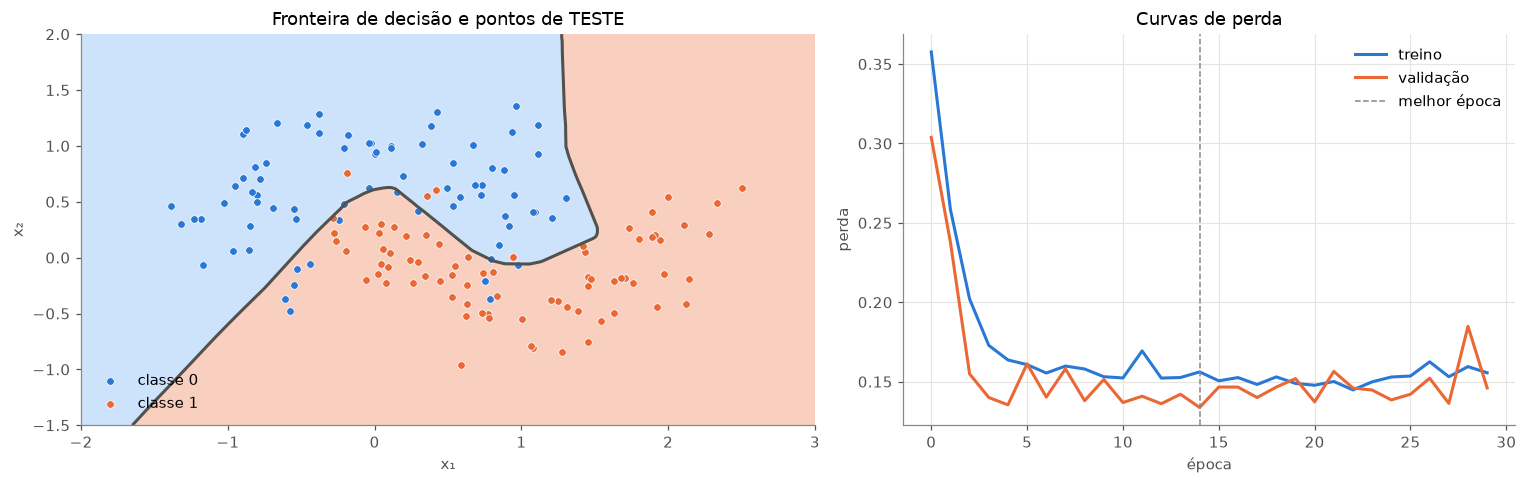

In [20]:
# fronteira de decisão, a grade é padronizada com a média e o desvio do TREINO, como os dados
g1, g2 = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.5, 2, 300))
grade = torch.tensor(np.c_[g1.ravel(), g2.ravel()], dtype=torch.float32)
with torch.no_grad():
    prob = torch.softmax(modelo_luas((grade - dm_luas.x_media) / dm_luas.x_desvio), dim=1)[:, 1].reshape(300, 300)

X_teste_luas = dm_luas.teste.tensors[0] * dm_luas.x_desvio + dm_luas.x_media      # volta à escala original
y_teste_luas = dm_luas.teste.tensors[1]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), width_ratios=[1.2, 1])
axes[0].contourf(g1, g2, prob, levels=[0, 0.5, 1], colors=["#cde2fb", "#f9d0bf"])
axes[0].contour(g1, g2, prob, levels=[0.5], colors=TINTA, linewidths=2)
axes[0].grid(False)
for classe, cor in [(0, AZUL), (1, LARANJA)]:
    m = y_teste_luas == classe
    axes[0].scatter(X_teste_luas[m, 0], X_teste_luas[m, 1], s=25, color=cor, edgecolor="white", lw=0.5, label=f"classe {classe}")
axes[0].set(title="Fronteira de decisão e pontos de TESTE", xlabel="x₁", ylabel="x₂")
axes[0].legend(frameon=False, loc="lower left")
plota_perda(trainer_luas, axes[1], "Curvas de perda")
plt.tight_layout()
plt.show()

## 5. Problema 2: regressão em tabela (diabetes)

O dataset `diabetes` do scikit-learn tem 442 pacientes, 10 medidas clínicas (idade, IMC, pressão, exames de
sangue...) e o alvo é um índice de **progressão da doença** um ano depois. Agora é **regressão**, a rede devolve
um número, e a perda muda para o erro quadrático médio.

| Peça | Escolha |
|---|---|
| Dados | 442 linhas, 10 features; `X` e `y` padronizados (com a média e o desvio do treino) |
| Rede | MLP 10 → 64 → 64 → 1 |
| Perda | `nn.MSELoss()` |

Repare que **a função `treina` é a mesma** do problema anterior: só mudaram os dados, a rede e a perda.

In [22]:
diabetes = load_diabetes()
dm_diab = TabelaDataModule(torch.tensor(diabetes.data), torch.tensor(diabetes.target).float().unsqueeze(1),
                           batch_size=32, padroniza_y=True)

torch.manual_seed(0)

## cria a rede aqui 
rede_diab = nn.Sequential(nn.Linear(10, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1))

## fita a rede com a loss e a metrica 
modelo_diab = ModeloGenerico(rede_diab, nn.MSELoss(), metricas={"mae": mae}, lr=1e-3)
trainer_diab = treina(modelo_diab, dm_diab, "diabetes", max_epocas=300, paciencia=20)

[diabetes] 38 épocas em 0 s; melhor época: 17
[diabetes] teste: teste_perda = 0.6152   teste_mae = 0.6170


Para interpretar, usamos o `trainer.predict` e **desfazemos a padronização** de `y`, voltando à unidade
original do índice. Comparamos com um *baseline* que sempre prevê a média do treino:

erro absoluto médio no teste: rede = 47.2   baseline (média do treino) = 68.6


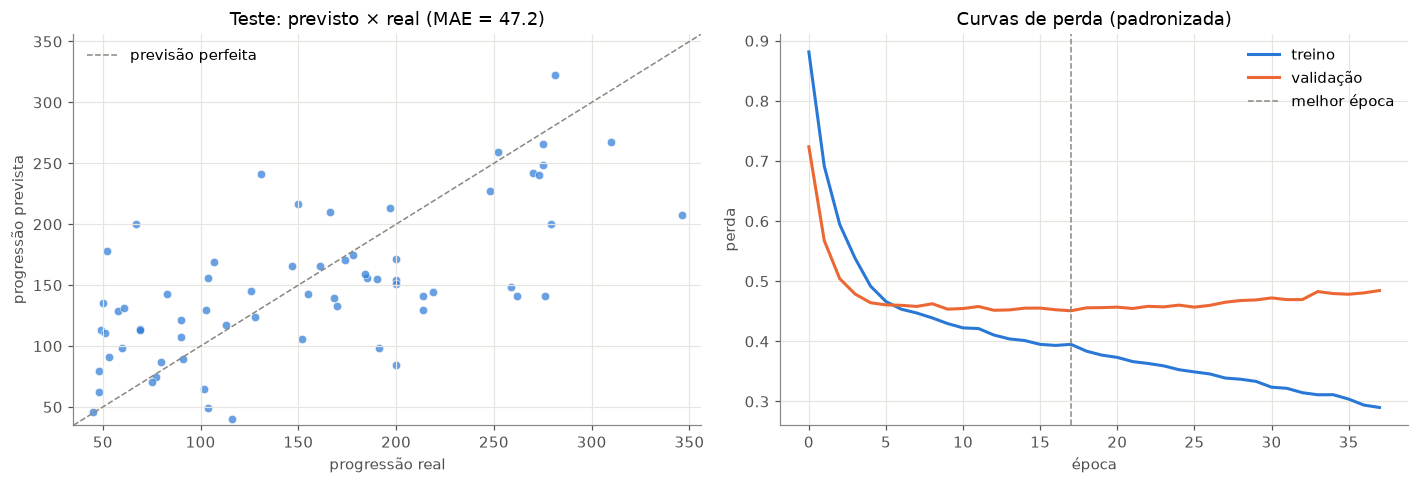

In [24]:
previsto = torch.cat(trainer_diab.predict(modelo_diab, dataloaders=dm_diab.test_dataloader()))
previsto = previsto * dm_diab.y_desvio + dm_diab.y_media
real = dm_diab.teste.tensors[1] * dm_diab.y_desvio + dm_diab.y_media

mae_rede = (previsto - real).abs().mean().item()
mae_base = (dm_diab.y_media - real).abs().mean().item()
print(f"erro absoluto médio no teste: rede = {mae_rede:.1f}   baseline (média do treino) = {mae_base:.1f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(real, previsto, s=30, color=AZUL, alpha=0.7, edgecolor="white", lw=0.5)
lim = [real.min().item() - 10, real.max().item() + 10]
axes[0].plot(lim, lim, color=CINZA, ls="--", lw=1, label="previsão perfeita")
axes[0].set(xlim=lim, ylim=lim, xlabel="progressão real", ylabel="progressão prevista",
            title=f"Teste: previsto × real (MAE = {mae_rede:.1f})")
axes[0].legend(frameon=False)
plota_perda(trainer_diab, axes[1], "Curvas de perda (padronizada)")
plt.tight_layout()
plt.show()

A rede erra, em média, ~47 pontos do índice, contra ~69 do *baseline*: aprendeu algo útil, mas a tabela é pequena
(442 pacientes) e o problema é difícil. Repare também nas curvas: a perda de **validação** para de melhorar
por volta da época 17 enquanto a de treino continua caindo (início de *overfitting*). O `EarlyStopping`
esperou 20 épocas sem melhora (`paciencia=20`), parou o treino e o teste usou o **melhor** checkpoint, não o último.

## 6. Problema 3: previsão de série temporal (LSTM)

Uma série sintética, como uma medição de sensor: a soma de dois ciclos mais ruído. A tarefa: **olhando os 30
últimos valores, prever o próximo**. Cada amostra é uma janela de 30 valores, e o alvo é o valor seguinte.

| Peça | Escolha |
|---|---|
| Dados | janelas de 30 passos; divisão **temporal** (treino = passado, teste = futuro), como na aula de balneabilidade |
| Rede | **LSTM**, uma rede recorrente feita para sequências (veremos em detalhe nas próximas aulas) |
| Perda | `nn.MSELoss()` |

A LSTM tem uma interface diferente do `nn.Sequential`, então a embrulhamos em uma pequena classe. Para o
`ModeloGenerico`, isso não faz diferença: ele só precisa de algo que receba `x` e devolva a previsão.

In [25]:
t = torch.arange(2000, dtype=torch.float32)
torch.manual_seed(0)
serie = torch.sin(2 * np.pi * t / 50) + 0.5 * torch.sin(2 * np.pi * t / 17) + 0.1 * torch.randn(2000)

JANELA = 30
X_serie = torch.stack([serie[i:i + JANELA] for i in range(len(serie) - JANELA)])   # (1970, 30)
y_serie = serie[JANELA:].unsqueeze(1)                                               # (1970, 1)
dm_serie = TabelaDataModule(X_serie, y_serie, batch_size=64, padroniza_x=False, temporal=True)


class PrevisorLSTM(nn.Module):
    def __init__(self, oculto=32):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=oculto, batch_first=True)
        self.saida = nn.Linear(oculto, 1)

    def forward(self, x):                        # x: (lote, 30)
        h, _ = self.lstm(x.unsqueeze(-1))        # (lote, 30, 1) - (lote, 30, oculto)
        return self.saida(h[:, -1])              # usa o estado do último passo - (lote, 1)


torch.manual_seed(0)
modelo_serie = ModeloGenerico(PrevisorLSTM(), nn.MSELoss(), metricas={"mae": mae}, lr=5e-3)
trainer_serie = treina(modelo_serie, dm_serie, "serie_temporal", max_epocas=100, paciencia=10)

[serie_temporal] 43 épocas em 3 s; melhor época: 32
[serie_temporal] teste: teste_perda = 0.0130   teste_mae = 0.0880


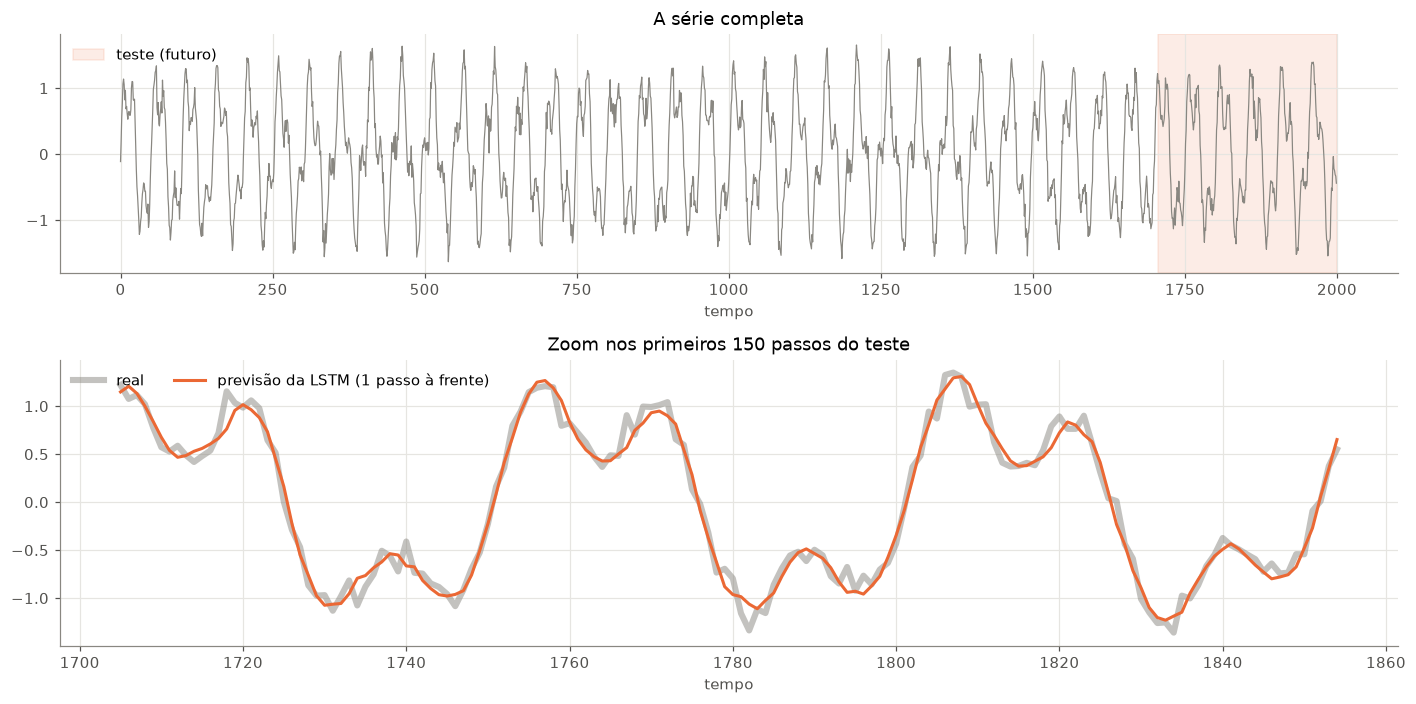

In [26]:
previsto_serie = torch.cat(trainer_serie.predict(modelo_serie, 
                                                 dataloaders=dm_serie.test_dataloader()
                                                 )
                        )
real_serie = dm_serie.teste.tensors[1]
inicio_teste = len(serie) - len(real_serie)

fig, axes = plt.subplots(2, 1, figsize=(13, 6.5), height_ratios=[1, 1.2])
axes[0].plot(t, serie, color=CINZA, lw=0.8)
axes[0].axvspan(inicio_teste, len(serie), color=LARANJA, alpha=0.12, label="teste (futuro)")
axes[0].set(title="A série completa", xlabel="tempo")
axes[0].legend(frameon=False, loc="upper left")
trecho = slice(0, 150)
tt = t[inicio_teste:][trecho]
axes[1].plot(tt, real_serie[trecho], color=CINZA, lw=4, alpha=0.5, label="real")
axes[1].plot(tt, previsto_serie[trecho], color=LARANJA, lw=2, label="previsão da LSTM (1 passo à frente)")
axes[1].set(title="Zoom nos primeiros 150 passos do teste", xlabel="tempo")
axes[1].legend(frameon=False, loc="upper left", ncols=2)
plt.tight_layout()
plt.show()

## 7. Problema 4: classificação de imagens (rede convolucional)

De volta ao MNIST, mas agora com uma **rede convolucional** (CNN) em vez do MLP. A CNN olha para pequenas
regiões da imagem (3 × 3 pixels) e aproveita a estrutura espacial, que o MLP perdia ao achatar a imagem. O
detalhe das convoluções fica para a próxima aula, hoje vamos tentar só olhar para a estrutura da rede no lightning.

| Peça | Escolha |
|---|---|
| Dados | `MNISTDataModule`: 55 mil treino, 5 mil validação, 10 mil teste |
| Rede | 2 camadas convolucionais + 1 camada linear |
| Perda | `nn.CrossEntropyLoss()` |

### Superpoder: a busca de taxa de aprendizado

Em vez de chutar o `lr`, o `Tuner` treina por 100 passos aumentando o `lr` de forma exponencial (de 0,000001 até 1)
e registra a perda. Uma boa taxa fica na região em que a perda **cai mais rápido**, antes de ela explodir.

  | Name   | Type             | Params | Mode  | FLOPs
------------------------------------------------------------
0 | rede   | Sequential       | 20.5 K | train | 0    
1 | rede.0 | Conv2d           | 160    | train | 0    
2 | rede.1 | ReLU             | 0      | train | 0    
3 | rede.2 | MaxPool2d        | 0      | train | 0    
4 | rede.3 | Conv2d           | 4.6 K  | train | 0    
5 | rede.4 | ReLU             | 0      | train | 0    
6 | rede.5 | MaxPool2d        | 0      | train | 0    
7 | rede.6 | Flatten          | 0      | train | 0    
8 | rede.7 | Linear           | 15.7 K | train | 0    
9 | perda  | CrossEntropyLoss | 0      | train | 0    
------------------------------------------------------------
20.5 K    Trainable params
0         Non-trainable params
20.5 K    Total params
0.082     Total estimated model params size (MB)
10        Modules in train mode
0         Modules in eval mode
0         Total Flops


Finding best initial lr:   0%|          | 0/100 [00:00<?, ?it/s]

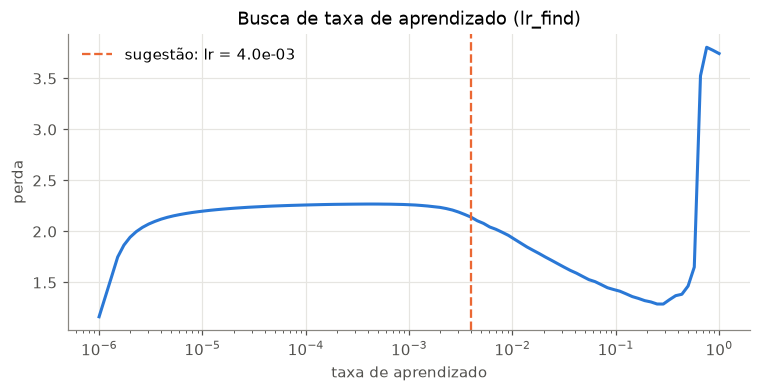

o lr do modelo foi atualizado automaticamente para 4.0e-03


In [27]:
dm_mnist = MNISTDataModule(batch_size=128)

torch.manual_seed(0)

## criando a rede com convoluções, vamos olhar mais fundo semana q vem
rede_cnn = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # (1, 28, 28) - (16, 14, 14)
    nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # - (32, 7, 7)
    nn.Flatten(), nn.Linear(32 * 7 * 7, 10),
)

# de novo, fitamos nos modelo com as metriacs
modelo_cnn = ModeloGenerico(rede_cnn, nn.CrossEntropyLoss(), metricas={"acc": acuracia})
print(ModelSummary(modelo_cnn, max_depth=2))


tuner = Tuner(L.Trainer(max_epochs=1, 
                        accelerator=ACELERADOR, 
                        logger=False, 
                        enable_progress_bar=False,
                        enable_model_summary=False, 
                        default_root_dir="logs/dl5/lr_find")
                        )
with contextlib.redirect_stderr(io.StringIO()):            # esconde a barra de progresso da busca
    busca_lr = tuner.lr_find(modelo_cnn, 
                             datamodule=dm_mnist, 
                             min_lr=1e-6, 
                             max_lr=1.0, 
                             num_training=100
                             )

r = busca_lr.results
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(r["lr"], r["loss"], color=AZUL, lw=2)
ax.axvline(busca_lr.suggestion(), color=LARANJA, ls="--", lw=1.5, label=f"sugestão: lr = {busca_lr.suggestion():.1e}")
ax.set(xscale="log", xlabel="taxa de aprendizado", ylabel="perda", title="Busca de taxa de aprendizado (lr_find)")
ax.legend(frameon=False)
plt.show()
print(f"o lr do modelo foi atualizado automaticamente para {modelo_cnn.lr:.1e}")

A sugestão é uma **heurística**: sempre olhe a curva. Valores abaixo dela aprendem devagar; valores perto do ponto
em que a perda explode são instáveis. Com o `lr` sugerido já aplicado ao modelo, treinamos por 3 épocas
(cerca de 20 segundos na CPU):

In [28]:
trainer_cnn = treina(modelo_cnn, 
                     dm_mnist, 
                     "mnist_cnn", 
                     max_epocas=3, 
                     paciencia=2
                     )

[mnist_cnn] 3 épocas em 19 s; melhor época: 2
[mnist_cnn] teste: teste_perda = 0.0371   teste_acc = 0.9879


Na aula 4, o MLP chegou a ~97% de acurácia no teste. A CNN, com **menos parâmetros**, passa disso em poucas
épocas.

### Superpoder: recarregar o melhor modelo salvo

O `ModelCheckpoint` salvou o melhor modelo em disco. Qualquer pessoa pode recarregá-lo depois (em outro
notebook, em um servidor) e usá-lo para prever. Como a rede foi passada como argumento, informamos a arquitetura
ao carregar:

melhor modelo salvo em: logs/dl5/mnist_cnn/version_2/checkpoints/epoch=2-step=1290.ckpt


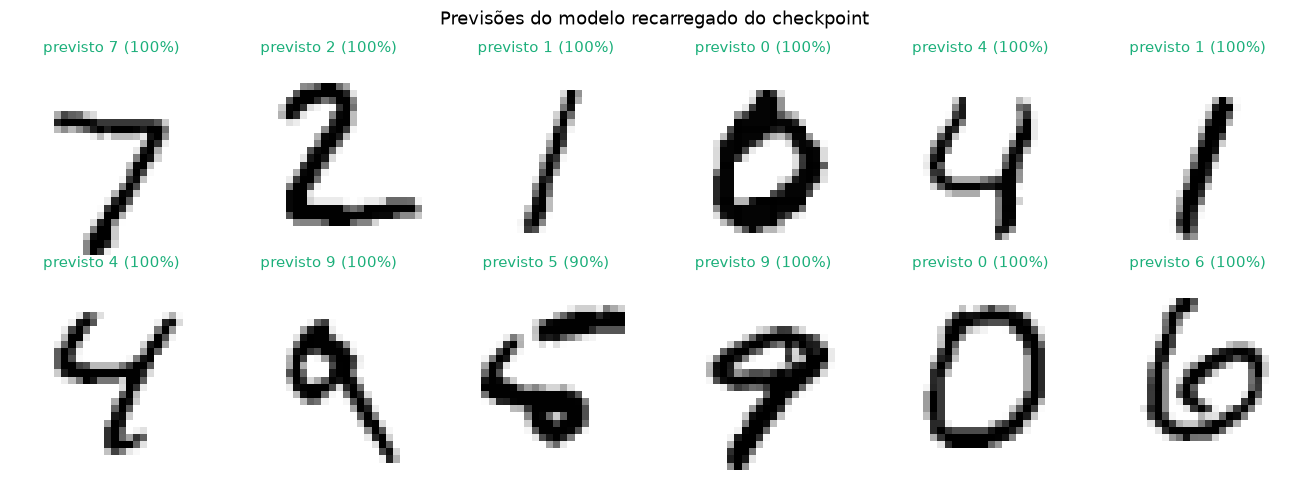

In [29]:
caminho = trainer_cnn.checkpoint_callback.best_model_path
print(f"melhor modelo salvo em: {caminho}")

# aqui recarregamos os melhores pesos durante o treino 
recarregado = ModeloGenerico.load_from_checkpoint(caminho, rede=rede_cnn, perda=nn.CrossEntropyLoss())
## evaluation mode, isso significa que os pesos nao serao mais atualizados 
recarregado.eval()

x_ex, y_ex = next(iter(dm_mnist.test_dataloader()))
with torch.no_grad():
    prob_ex = torch.softmax(recarregado(x_ex[:12]), dim=1)

fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for ax, img, y, p in zip(axes.flat, x_ex[:12], y_ex[:12], prob_ex):
    pred = p.argmax().item()
    ax.imshow(img[0], cmap="gray_r")
    ax.set_title(f"previsto {pred} ({p[pred]:.0%})", color=VERDE if pred == y else LARANJA, fontsize=10)
    ax.axis("off")
plt.suptitle("Previsões do modelo recarregado do checkpoint")
plt.tight_layout()
plt.show()

## 8. Problema 5: autoencoder, aprendendo sem rótulos

E se não houver rótulos? Um **autoencoder** aprende a **comprimir** a imagem em poucos números (o *código* ou
*espaço latente*) e depois **reconstruí-la** a partir deles. O alvo é a própria imagem, então não precisa de
rótulo nenhum: é aprendizado **não supervisionado**, como o clustering da aula de ML.

| Peça | Escolha |
|---|---|
| Dados | `MNISTDataModule(autoencoder=True)`: cada amostra é `(imagem, imagem)` |
| Rede | codificador 784 → 128 → **2** e decodificador 2 → 128 → 784 |
| Perda | `nn.MSELoss()` entre a imagem reconstruída e a original |

Comprimimos cada imagem de 784 pixels em apenas **2 números**, para poder desenhar o espaço latente.

In [30]:
class Autoencoder(nn.Module):
    def __init__(self, dim_latente=2):
        super().__init__()
        self.codificador = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, dim_latente))
        self.decodificador = nn.Sequential(nn.Linear(dim_latente, 128), nn.ReLU(), nn.Linear(128, 784), nn.Sigmoid())

    def forward(self, x):
        z = self.codificador(x)                                  # (lote, 2): a imagem comprimida
        return self.decodificador(z).reshape(-1, 1, 28, 28)      # reconstrução com o formato da entrada


dm_ae = MNISTDataModule(batch_size=128, autoencoder=True)
torch.manual_seed(0)
autoencoder = Autoencoder()
modelo_ae = ModeloGenerico(autoencoder, nn.MSELoss(), lr=2e-3)
trainer_ae = treina(modelo_ae, dm_ae, "autoencoder", max_epocas=10, paciencia=3)

[autoencoder] 10 épocas em 13 s; melhor época: 9
[autoencoder] teste: teste_perda = 0.0422


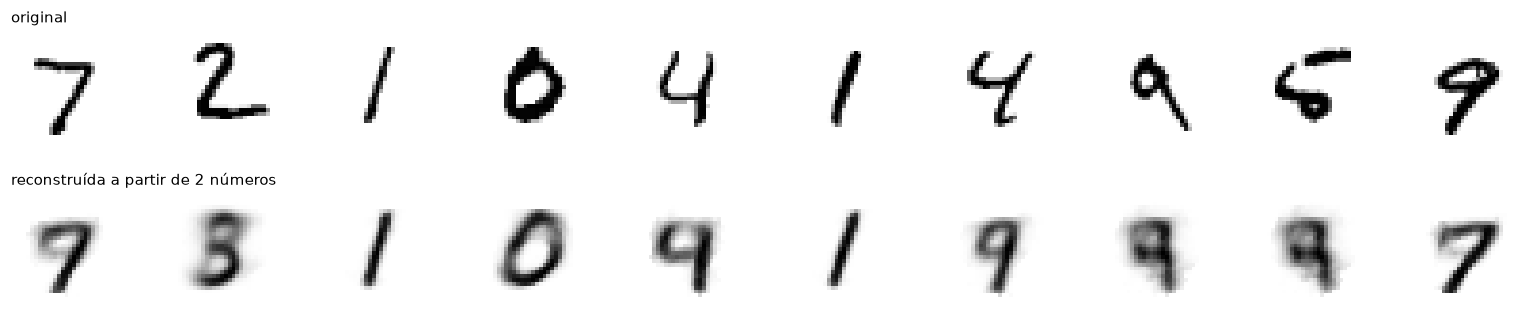

In [31]:
x_ae, _ = next(iter(dm_ae.test_dataloader()))
with torch.no_grad():
    reconstruido = modelo_ae(x_ae[:10])

fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for j in range(10):
    axes[0, j].imshow(x_ae[j, 0], cmap="gray_r")
    axes[1, j].imshow(reconstruido[j, 0], cmap="gray_r")
    axes[0, j].axis("off"); axes[1, j].axis("off")
axes[0, 0].set_title("original", loc="left", fontsize=10)
axes[1, 0].set_title("reconstruída a partir de 2 números", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

As reconstruções são borradas: 2 números é **muito** pouco para guardar uma imagem. Os dígitos com formas
bem distintas (0, 1, 7) voltam reconhecíveis, mas vários viram um dígito **parecido** (um 2 vira algo como um 3,
um 4 vira um 9). O mais interessante é o **espaço latente**: onde cada imagem do teste foi parar no plano de 2
dimensões? O autoencoder **nunca viu os rótulos**, mas vamos colorir os pontos pelo dígito verdadeiro:

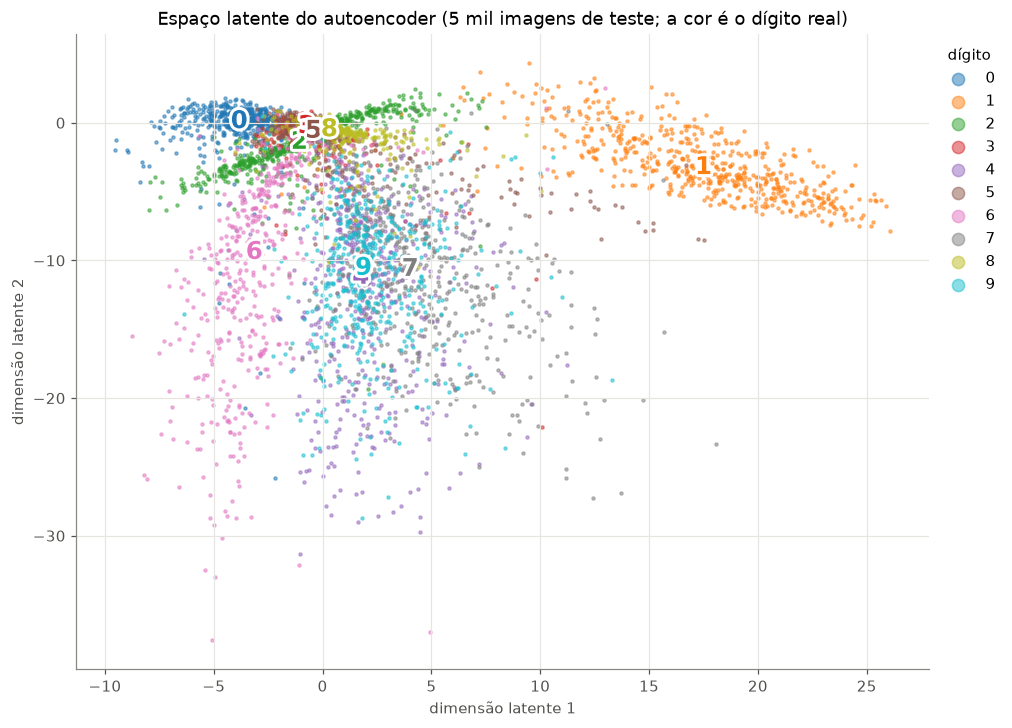

In [32]:
teste_mnist = datasets.MNIST("data", train=False, transform=transforms.ToTensor())
x_todos = torch.stack([teste_mnist[i][0] for i in range(5000)])
rotulos = teste_mnist.targets[:5000]
with torch.no_grad():
    z = autoencoder.codificador(x_todos)

import matplotlib.patheffects as pe

fig, ax = plt.subplots(figsize=(10, 7.5))
cores_digitos = plt.get_cmap("tab10")
for d in range(10):
    m = rotulos == d
    ax.scatter(z[m, 0], z[m, 1], s=4, color=cores_digitos(d), alpha=0.5, label=str(d))
    cx, cy = z[m].median(dim=0).values
    ax.text(cx, cy, str(d), fontsize=16, fontweight="bold", ha="center", va="center", color=cores_digitos(d),
            path_effects=[pe.withStroke(linewidth=4, foreground="white")])
ax.legend(title="dígito", frameon=False, markerscale=4, loc="upper left", bbox_to_anchor=(1, 1))
ax.set(xlabel="dimensão latente 1", ylabel="dimensão latente 2",
       title="Espaço latente do autoencoder (5 mil imagens de teste; a cor é o dígito real)")
plt.show()

Sem nunca ter visto um rótulo, o autoencoder **organizou** o espaço latente por forma: o 0, o 1 e o 6 ficam em
regiões próprias, enquanto dígitos de traçado parecido se misturam, como 4, 7 e 9, ou 3, 5 e 8. As mesmas
confusões aparecem nas reconstruções acima. Essa é a mesma intuição da aula de aprendizado não
supervisionado, agora com uma rede neural.

## 9. O que mudou entre os cinco problemas?

| Problema | Dados (`DataModule`) | Rede | Perda | Métrica |
|---|---|---|---|---|
| Duas luas | `TabelaDataModule`, divisão aleatória | MLP | `CrossEntropyLoss` | acurácia |
| Diabetes | `TabelaDataModule`, `padroniza_y=True` | MLP | `MSELoss` | MAE |
| Série temporal | `TabelaDataModule`, `temporal=True` | LSTM | `MSELoss` | MAE |
| Dígitos | `MNISTDataModule` | CNN | `CrossEntropyLoss` | acurácia |
| Autoencoder | `MNISTDataModule(autoencoder=True)` | codificador + decodificador | `MSELoss` | — |

O `ModeloGenerico` e a função `treina` **não mudaram uma linha**. *Early stopping*, *checkpoint*, registro das
métricas, avaliação com o melhor modelo e GPU vieram de graça em todos os casos. É isso que significa dizer que,
com as três peças certas, dá para treinar uma rede neural para (quase) qualquer coisa.

## 10. Discussão

- `LightningDataModule` organiza os dados: download, divisão, padronização e `DataLoader`s em um só objeto.
- Um `LightningModule` pode ser **genérico**: receber a rede, a perda e as métricas como argumentos.
- O `Trainer` concentra o código repetitivo: *early stopping*, *checkpoints*, *logging*, aceleradores, precisão mista.
- `fast_dev_run=True` é o melhor amigo de quem programa: encontra bugs em segundos.
- `Tuner.lr_find` sugere uma taxa de aprendizado em vez de chutar (mas olhe sempre a curva).
- O que define o problema são os **dados**, a **rede** e a **perda**; o resto é infraestrutura.

### Exercícios

1. **Um sexto problema:** use `sklearn.datasets.load_wine` (178 vinhos, 13 features, 3 classes) com o
   `TabelaDataModule` e o `ModeloGenerico`. Quantas linhas de código novas você precisou?
2. Treine o problema das duas luas com `L.Trainer(overfit_batches=1, max_epochs=200)`. A perda de treino chega
   perto de zero? Por que esse é um bom teste de depuração?
3. Troque o `CSVLogger` por `TensorBoardLogger` e abra o painel com `%load_ext tensorboard` e `%tensorboard --logdir logs`.
4. No autoencoder, troque `dim_latente=2` por `dim_latente=16`. As reconstruções melhoram? (Para visualizar o
   espaço latente de 16 dimensões, você precisaria de PCA ou t-SNE.)
5. Na série temporal, troque a `PrevisorLSTM` por um MLP `nn.Sequential(nn.Linear(30, 64), nn.ReLU(), nn.Linear(64, 1))`.
   Qual tem o menor erro no teste?

## 11. Acompanhando o treino no Weights & Biases (W&B)

Até aqui as métricas foram para um CSV na pasta `logs/`. Em projetos reais, com dezenas de experimentos, isso fica
difícil de acompanhar. O **[Weights & Biases](https://wandb.ai)** (W&B) é uma plataforma online (gratuita para uso
pessoal e acadêmico) que recebe as métricas **durante** o treino e mostra tudo em um painel no navegador:

- curvas de perda e métricas **ao vivo**, época a época;
- **comparação** entre execuções (qual `lr`, qual rede, qual otimizador foi melhor?);
- os **hiperparâmetros** de cada execução, o uso de CPU/GPU e memória;
- os **checkpoints** do modelo guardados na nuvem (`log_model=True`);
- *sweeps*: busca automática de hiperparâmetros.

Com o Lightning, conectar o W&B é trocar **uma linha**: o `logger` do `Trainer`.

```python
# antes
logger = CSVLogger("logs/dl5", name="mnist_cnn")
# depois
logger = WandbLogger(project="spacetech-dl5", name="mnist_cnn")
```

Os `self.log(...)` do `ModeloGenerico` não mudam: o Lightning envia os mesmos valores para o W&B.

### Passo a passo

1. Crie uma conta em [wandb.ai](https://wandb.ai) (dá para entrar com a conta do GitHub ou do Google).
2. Copie a sua chave de API em [wandb.ai/authorize](https://wandb.ai/authorize).
3. Instale a biblioteca: `uv add wandb` no projeto (ou `pip install wandb` no Colab).
4. Na célula abaixo, mude `USAR_WANDB = True` e execute. Na primeira vez, o `wandb.login()` pede a chave de API
   (ela fica salva no computador; não coloque a chave no código nem no GitHub).
5. A célula imprime um link para a execução: abra no navegador e acompanhe as curvas enquanto a rede treina.

> **Sem internet?** Use `os.environ["WANDB_MODE"] = "offline"` antes de treinar. Os dados ficam na pasta `wandb/`
> e podem ser enviados depois com `wandb sync wandb/offline-run-*`.

In [21]:
USAR_WANDB = False   # ← mude para True depois de criar a conta e instalar o wandb

if USAR_WANDB:
    import wandb
    from lightning.pytorch.loggers import WandbLogger

    wandb.login()                                         # pede a chave de API na primeira vez

    logger_wandb = WandbLogger(
        project="spacetech-dl5",                          # agrupa as execuções em um projeto
        name="mnist_cnn_adam",                            # nome desta execução no painel
        log_model=True,                                   # envia o melhor checkpoint para a nuvem
    )
    logger_wandb.experiment.config.update({"batch_size": 128, "rede": "CNN 16-32", "otimizador": "Adam"})

    torch.manual_seed(0)
    rede_wandb = nn.Sequential(                           # a mesma CNN do problema 4, com pesos novos
        nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Linear(32 * 7 * 7, 10),
    )
    modelo_wandb = ModeloGenerico(rede_wandb, nn.CrossEntropyLoss(), metricas={"acc": acuracia}, lr=4e-3)

    trainer_wandb = L.Trainer(
        max_epochs=3,
        accelerator=ACELERADOR,
        logger=logger_wandb,                              # ← a única diferença para a função treina
        callbacks=[EarlyStopping(monitor="val_perda", patience=2), ModelCheckpoint(monitor="val_perda", mode="min")],
    )
    trainer_wandb.fit(modelo_wandb, datamodule=dm_mnist)
    trainer_wandb.test(modelo_wandb, datamodule=dm_mnist, ckpt_path="best")
    wandb.finish()                                        # encerra a execução e termina o envio
else:
    print("W&B desligado. Siga o passo a passo acima e mude USAR_WANDB = True para ver o treino no painel.")

W&B desligado. Siga o passo a passo acima e mude USAR_WANDB = True para ver o treino no painel.


No painel do W&B você verá, entre outras coisas, os gráficos `treino_perda`, `val_perda`, `treino_acc` e `val_acc`
(os mesmos nomes do `self.log`), a aba **Overview** com os hiperparâmetros e a aba **System** com o uso de CPU e
memória. Treine de novo mudando o `lr` ou a rede e compare as execuções lado a lado: é assim que equipes de
Deep Learning organizam centenas de experimentos.